# Trabajo Práctico 1: el modelo de neuronas de Izhikevich

El objetivo es integrar el modelo de Izhikevich con RK4 y reproducir los patrones de disparo de la figura 2 del artículo original (primera parte del práctico).

## El modelo de Izhikevich

El modelo de Izhikevich (ref. 1) es una simplificación del conocido modelo que Hodgkin y Huxley introdujeron en 1952 (ref. 2, premio Nobel de Fisiología y Medicina de 1963) para describir el comportamiento del potencial de disparo de una neurona.

El modelo se describe en términos de la siguiente ODE bidimensional y de primer orden

$$
\begin{array}{rcl}
v'(t) &=& 0.04\,v^2(t) + 5\,v(t) + 140 - u(t) + I(t) \\
u'(t) &=& a\,\big(b\,v(t) - u(t)\big)
\end{array}
$$

unida al mecanismo de *reseteo* del potencial

$$
\begin{array}{rcl}
v(t) &\leftarrow& c \\
u(t) &\leftarrow& u(t) + d
\end{array}
$$

el cual emula el disparo de la neurona, imponiéndose cuando se cumple la condición $v(t) \geq 30$ mV.

La variable $v$ representa el potencial de membrana (en mV) y $u$ es una variable de recuperación, que resume procesos iónicos lentos y aporta realimentación negativa sobre $v$. Los parámetros del modelo son:

- $a$: escala temporal de la recuperación de $u$.
- $b$: cuánto responde $u$ a las variaciones subumbrales de $v$.
- $c$: valor al que se resetea $v$ después de un disparo.
- $d$: incremento de $u$ después de un disparo.

Además, se considera la función dependiente del tiempo $I:\mathbb{R}\ni t\to I(t)\in \mathbb{R}$, que representa una corriente de entrada que excita a la neurona. El tiempo se mide en ms.

El valor $v = 30$ mV es el que usa el algoritmo para registrar el pico del disparo y aplicar el reseteo; no es un umbral fisiológico fijo. La iniciación del disparo depende del estado previo de $v$ y $u$.

La Guía 6 escribe el mismo modelo con otros nombres: $g_2 = 0.04$, $g_1 = 5$, $g_0 = 140$, $v_+ = 30$; la $b$ de la guía es aquí $a$, su $c$ es aquí $b$, $v_-$ es $c$ y $\Delta u$ es $d$.

Referencias:

1. [Eugene M. Izhikevich, Simple Model of Spiking Neurons, IEEE Transactions on Neural Networks, vol. 14, no. 6, p. 1569, noviembre 2003](https://ieeexplore.ieee.org/document/1257420) ([PDF de acceso libre](https://www.izhikevich.org/publications/spikes.pdf))
2. https://en.wikipedia.org/wiki/Hodgkin%E2%80%93Huxley_model

## Preparación del entorno en Colab
Ejecutá esta celda y autorizá el acceso con una cuenta que tenga permiso para leer la fuente del práctico. La fuente se descarga por su ID de Drive, independientemente de la carpeta donde esté guardada. Si ejecutás el notebook localmente, omití esta celda.

In [ ]:
import numpy                   as np
import matplotlib.pyplot       as plt
import matplotlib.font_manager as fm

Estilo de los gráficos

In [ ]:
FUENTE = 'Montserrat-Regular.ttf'

COLOR   = '#2a78d6'
NARANJA = '#eb6834'
FONDO   = '#fcfcfb'
GRILLA  = '#e4e3df'
TEXTO   = '#52514e'
TITULO  = '#0b0b0b'

fm.fontManager.addfont(FUENTE)

plt.rcParams.update(
                    {
                     'font.family'        : fm.FontProperties(fname = FUENTE).get_name(),
                     'figure.facecolor'   : '#ffffff',
                     'axes.facecolor'     : FONDO,
                     'axes.edgecolor'     : GRILLA,
                     'axes.grid'          : True,
                     'axes.axisbelow'     : True,
                     'axes.labelcolor'    : TEXTO,
                     'axes.titlecolor'    : TITULO,
                     'axes.titlelocation' : 'left',
                     'grid.color'         : GRILLA,
                     'grid.linewidth'     : 0.8,
                     'xtick.color'        : TEXTO,
                     'ytick.color'        : TEXTO,
                    }
                   )

## 1. Corriente de entrada

Inciso 1: $I_0(t) = 0$ si $t < 10$ ms e $I_0(t) = 10$ si $t \geq 10$ ms.

In [ ]:
def I0(t):
    if t < 10:
        return 0.0
    else:
        return 10.0

## 2. Parámetros, condición inicial y grilla de tiempo

Valores del inciso 1. La condición inicial $u(0) = b\,v(0)$ corresponde al reposo de la neurona. La lista `spikes` guarda los tiempos de disparo. La integración cubre $t \in [0, 100]$ ms con paso $h = 0.1$ ms, es decir $k = 1000$ pasos.

In [ ]:
v_pico = 30.0

p = {
     'a'      : 0.02,
     'b'      : 0.2,
     'c'      : -65.0,
     'd'      : 2.0,
     'I'      : I0,
     'spikes' : [],
    }

v0 = -70.0
u0 = p['b'] * v0
x0 = np.array([v0, u0])

t0 = 0.0
tf = 100.0
h  = 0.1
k  = round((tf - t0) / h)

print('Condición inicial (v, u):', x0)
print('Pasos de integración    :', k)

Condición inicial (v, u): [-70. -14.]
Pasos de integración    : 1000


## 3. Ecuaciones del modelo

`f_izh` devuelve $(v', u')$ con la firma `f(x, t, p)` que espera el integrador. En el reposo, antes del estímulo, las dos derivadas deben ser cero.

In [ ]:
def f_izh(x, t, p):
    v = x[0]
    u = x[1]

    dv = 0.04 * v**2 + 5 * v + 140 - u + p['I'](t)
    du = p['a'] * (p['b'] * v - u)

    return np.array([dv, du])


print('Derivadas en t = 0 :', f_izh(x0, 0, p))

Derivadas en t = 0 : [0. 0.]


## 4. Reseteo

Se usa como función condicionante del integrador: después de cada paso, si $v \geq 30$ mV, registra el disparo y aplica $v \leftarrow c$, $u \leftarrow u + d$.

In [ ]:
def reseteo(x, t, p):
    if x[0] >= v_pico:
        p['spikes'].append(t)

        x[0] = p['c']
        x[1] = x[1] + p['d']

    return x

## 5. Integrador

`rk4` calcula un paso del método de Runge-Kutta de orden 4: dado $x(t)$, devuelve $x(t+h)$. `integrador_ode` (de la Guía 4) repite ese paso `k` veces y, después de cada uno, aplica la función condicionante `c`, que acá será `reseteo`. Devuelve los tiempos `t` y la matriz `w`, cuya fila 0 es $v$ y la fila 1 es $u$.

In [ ]:
def rk4(f, x, t, h, p):
    k1 = f(x, t, p)
    k2 = f(x + 0.5 * h * k1, t + 0.5 * h, p)
    k3 = f(x + 0.5 * h * k2, t + 0.5 * h, p)
    k4 = f(x + h * k3, t + h, p)

    return x + h * (k1 + 2.0 * k2 + 2.0 * k3 + k4) / 6.0


def integrador_ode(m, f, xa, t_ini, t_fin, k, p, c = lambda x, t, p: x):
    n = len(xa)
    h = (t_fin - t_ini) / k

    t = np.zeros(k + 1)
    w = np.zeros((n, k + 1))

    t[0]    = t_ini
    w[:, 0] = xa

    for j in range(k):
        t[j + 1]    = t[j] + h                         # avanza el tiempo
        w[:, j + 1] = m(f, w[:, j], t[j], h, p)        # un paso del método (rk4)
        w[:, j + 1] = c(w[:, j + 1], t[j + 1], p)      # función condicionante (reseteo)

    return t, w

## 6. Integración (inciso 1)

Se vacía la lista de disparos y se integra con RK4 sobre $t \in [0, 100]$ ms. La fila 0 de `w` es $v(t)$ y la fila 1 es $u(t)$.

In [ ]:
p['spikes'] = []

t, w = integrador_ode(rk4, f_izh, x0, t0, tf, k, p, reseteo)

v      = w[0, :]
u      = w[1, :]
spikes = np.array(p['spikes'])

print('Disparos                :', len(spikes))
print('Tiempos de disparo (ms) :', spikes.round(1))

Disparos                : 7
Tiempos de disparo (ms) : [13.5 17.1 21.9 29.5 44.7 63.7 82.6]


## 7. Gráfico de $v$, $u$ e $I$ (inciso 2)

Un panel por magnitud, con el eje de tiempo compartido. La línea punteada marca el inicio del estímulo.

El reseteo se aplica en el mismo paso en que $v$ supera 30 mV, así que el valor guardado en ese instante ya es $c$ y el pico no queda en `v`. Para graficar, en cada disparo se inserta el punto $(t_{\text{spike}}, 30)$ justo antes del valor reseteado: la curva sube hasta 30 mV y desde ahí cae a $c$.

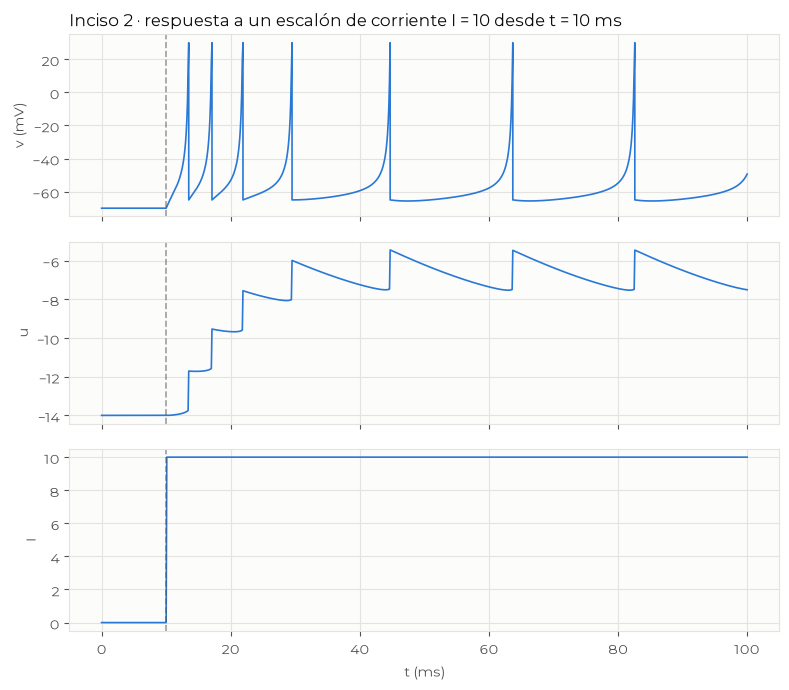

In [ ]:
t_estimulo = 10.0

I = np.zeros(len(t))

for j in range(len(t)):
    I[j] = p['I'](t[j])

indices_spike = np.searchsorted(t, spikes)

t_grafico = np.insert(t, indices_spike, spikes)
v_grafico = np.insert(v, indices_spike, v_pico)

fig, ax = plt.subplots(3, 1, sharex = True, figsize = (8, 7))

ax[0].plot(t_grafico, v_grafico, lw = 1.2, color = COLOR)
ax[0].set_title('Inciso 2 · respuesta a un escalón de corriente I = 10 desde t = 10 ms')
ax[0].set_ylabel('v (mV)')

ax[1].plot(t, u, lw = 1.2, color = COLOR)
ax[1].set_ylabel('u')

ax[2].plot(t, I, lw = 1.2, color = COLOR)
ax[2].set_ylabel('I')
ax[2].set_xlabel('t (ms)')

for eje in ax:
    eje.axvline(t_estimulo, ls = '--', lw = 1.2, color = TEXTO, alpha = 0.55)

plt.tight_layout()
plt.show()

## 8. Corrientes del inciso 3

Cada caso de la figura 2 se estimula con uno de cuatro protocolos de corriente:

| Corriente | Casos | Qué es |
|---|---|---|
| $I_1$ | RS, IB, CH, FS, LTS | Escalón fuerte desde los 20 ms |
| $I_2$ | TC1 | Escalón débil desde los 20 ms |
| $I_3$ | TC2 | Pulso negativo (hiperpolarizante) entre 20 y 80 ms |
| $I_4$ | RZ | Corriente chica constante desde los 40 ms, más un pulso de 1 ms a los 180 ms |

Los tramos se evalúan en orden: `elif` sólo se alcanza si las condiciones anteriores fallaron, por lo que alcanza con escribir el extremo superior de cada tramo.

In [ ]:
def I1(t):
    if t < 20:
        return 0.0
    else:
        return 10.0


def I2(t):
    if t < 20:
        return 0.0
    else:
        return 1.0


def I3(t):
    if t < 20:
        return 0.0
    elif t < 80:
        return -25.0
    else:
        return 0.0


def I4(t):
    if t < 40:
        return 0.0
    elif t < 180:
        return 0.2
    elif t < 181:
        return 2.2
    else:
        return 0.2

## 9. Parámetros de los ocho casos

Cada caso queda definido por sus parámetros $a, b, c, d$, la corriente que lo estimula, el potencial inicial $v(0)$ (con $u(0) = b\,v(0)$) y la duración de la simulación `tf`. La duración la elige el práctico; 200 ms alcanzan para ver cada patrón, salvo RZ, cuyo pulso llega a los 180 ms.

In [ ]:
casos = {
         'RS'  : {'a': 0.02, 'b': 0.20, 'c': -65.0, 'd': 8.00, 'I': I1, 'v0': -65.0, 'tf': 200.0},
         'IB'  : {'a': 0.02, 'b': 0.20, 'c': -55.0, 'd': 4.00, 'I': I1, 'v0': -65.0, 'tf': 200.0},
         'CH'  : {'a': 0.02, 'b': 0.20, 'c': -50.0, 'd': 2.00, 'I': I1, 'v0': -65.0, 'tf': 200.0},
         'FS'  : {'a': 0.10, 'b': 0.20, 'c': -65.0, 'd': 2.00, 'I': I1, 'v0': -65.0, 'tf': 200.0},
         'TC1' : {'a': 0.02, 'b': 0.25, 'c': -65.0, 'd': 0.05, 'I': I2, 'v0': -63.0, 'tf': 200.0},
         'TC2' : {'a': 0.02, 'b': 0.25, 'c': -65.0, 'd': 0.05, 'I': I3, 'v0': -65.0, 'tf': 200.0},
         'RZ'  : {'a': 0.10, 'b': 0.26, 'c': -65.0, 'd': 2.00, 'I': I4, 'v0': -62.5, 'tf': 300.0},
         'LTS' : {'a': 0.02, 'b': 0.25, 'c': -65.0, 'd': 2.00, 'I': I1, 'v0': -65.0, 'tf': 200.0},
        }

print('Casos:', list(casos.keys()))

Casos: ['RS', 'IB', 'CH', 'FS', 'TC1', 'TC2', 'RZ', 'LTS']


## 10. Los casos en el espacio de parámetros

Como en la figura 2 del artículo, cada caso se ubica en dos planos: $(a, b)$, que gobierna la dinámica de $u$, y $(c, d)$, que gobierna el reseteo. Varios casos comparten un mismo punto en un plano y se distinguen en el otro, así que los nombres se agrupan por coordenada.

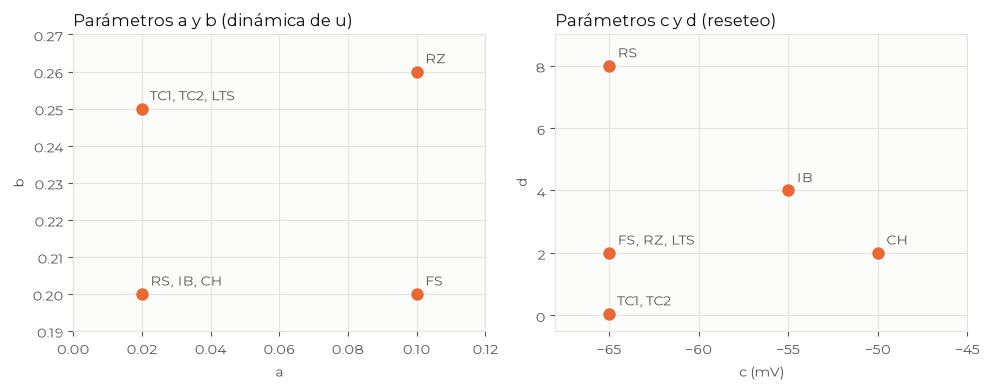

In [ ]:
grupos_ab = {}
grupos_cd = {}

for nombre in casos:
    caso = casos[nombre]

    punto_ab = (caso['a'], caso['b'])
    punto_cd = (caso['c'], caso['d'])

    if punto_ab not in grupos_ab:
        grupos_ab[punto_ab] = []
    if punto_cd not in grupos_cd:
        grupos_cd[punto_cd] = []

    grupos_ab[punto_ab].append(nombre)
    grupos_cd[punto_cd].append(nombre)

fig, ax = plt.subplots(1, 2, figsize = (10, 4))

for eje, grupos in [(ax[0], grupos_ab), (ax[1], grupos_cd)]:
    for punto in grupos:
        eje.scatter(punto[0], punto[1], s = 100, color = NARANJA, edgecolors = '#ffffff', zorder = 3)
        eje.annotate(
                     ', '.join(grupos[punto]),
                     punto,
                     xytext     = (6, 6),
                     textcoords = 'offset points',
                     color      = TEXTO,
                    )

ax[0].set_title('Parámetros a y b (dinámica de u)')
ax[0].set_xlabel('a')
ax[0].set_ylabel('b')
ax[0].set_xlim(0, 0.12)
ax[0].set_ylim(0.19, 0.27)

ax[1].set_title('Parámetros c y d (reseteo)')
ax[1].set_xlabel('c (mV)')
ax[1].set_ylabel('d')
ax[1].set_xlim(-68, -45)
ax[1].set_ylim(-0.5, 9)

plt.tight_layout()
plt.show()

## 11. Integración de los ocho casos

Para cada caso se arma el diccionario `p` con sus parámetros y su corriente, se vacía la lista de disparos y se integra con RK4 desde $v(0)$, $u(0) = b\,v(0)$ hasta `tf`, con el mismo paso $h = 0.1$ ms. Los resultados se guardan en `resultados`, con la misma estructura de diccionario de diccionarios que `casos`. Junto con $v$ se guarda la curva para graficar, con el pico en 30 mV insertado en cada disparo (sección 7).

In [ ]:
resultados = {}

for nombre in casos:
    caso = casos[nombre]

    p_caso = {
              'a'      : caso['a'],
              'b'      : caso['b'],
              'c'      : caso['c'],
              'd'      : caso['d'],
              'I'      : caso['I'],
              'spikes' : [],
             }

    x0_caso = np.array([caso['v0'], caso['b'] * caso['v0']])
    k_caso  = round((caso['tf'] - t0) / h)

    t_caso, w_caso = integrador_ode(rk4, f_izh, x0_caso, t0, caso['tf'], k_caso, p_caso, reseteo)

    spikes_caso   = np.array(p_caso['spikes'])
    indices_spike = np.searchsorted(t_caso, spikes_caso)

    resultados[nombre] = {
                          't'         : t_caso,
                          'v'         : w_caso[0, :],
                          'u'         : w_caso[1, :],
                          'spikes'    : spikes_caso,
                          't_grafico' : np.insert(t_caso, indices_spike, spikes_caso),
                          'v_grafico' : np.insert(w_caso[0, :], indices_spike, v_pico),
                         }

    print(f'{nombre:4s}: {len(spikes_caso):3d} disparos')

RS  :   5 disparos
IB  :   8 disparos
CH  :  17 disparos
FS  :  25 disparos
TC1 :   4 disparos
TC2 :   5 disparos
RZ  :   3 disparos
LTS :  17 disparos


## 12. Casos estimulados con $I_1$: RS, IB, CH, FS y LTS

Los cinco reciben el mismo escalón $I_1$ desde los 20 ms, así que las diferencias entre paneles se deben sólo a los parámetros. Los paneles comparten los ejes para poder compararlos; la línea punteada marca el inicio del estímulo.

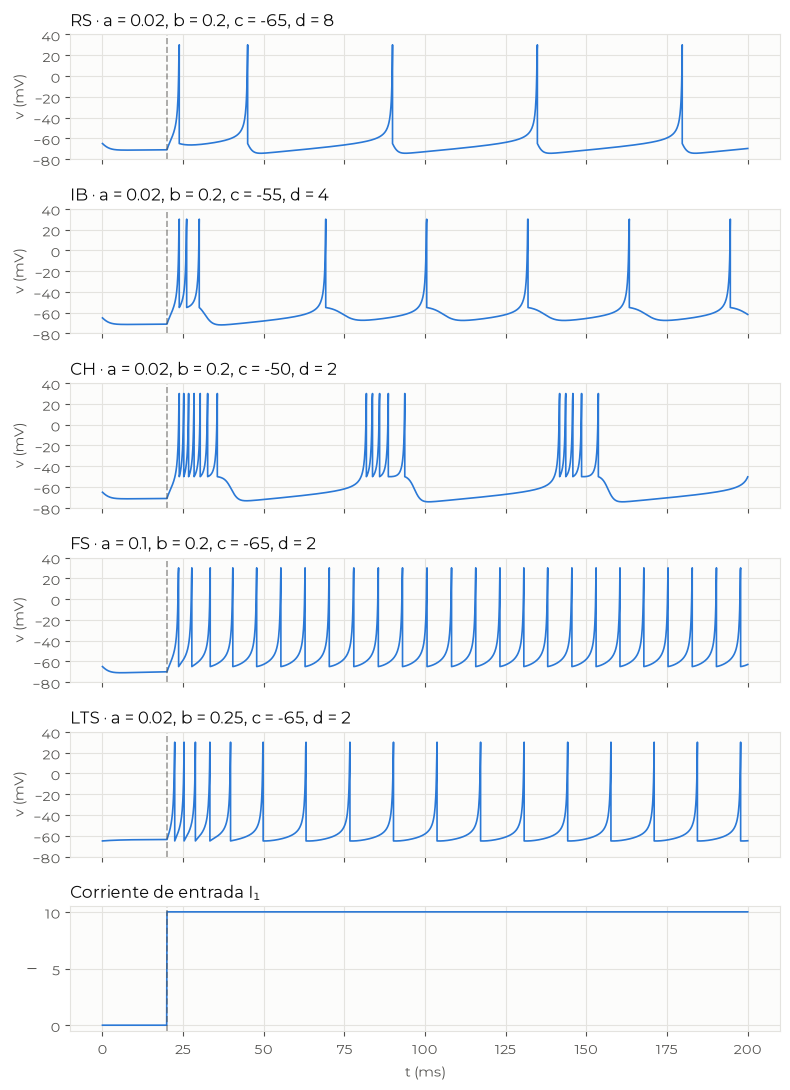

In [ ]:
casos_I1 = ['RS', 'IB', 'CH', 'FS', 'LTS']

fig, ax = plt.subplots(len(casos_I1) + 1, 1, sharex = True, figsize = (8, 11))

for i, nombre in enumerate(casos_I1):
    caso      = casos[nombre]
    resultado = resultados[nombre]

    ax[i].plot(resultado['t_grafico'], resultado['v_grafico'], lw = 1.2, color = COLOR)
    ax[i].set_title(f"{nombre} · a = {caso['a']}, b = {caso['b']}, c = {caso['c']:.0f}, d = {caso['d']:.0f}")
    ax[i].set_ylabel('v (mV)')
    ax[i].set_ylim(-80, 40)
    ax[i].set_yticks(np.arange(-80, 41, 20))

t_I1 = resultados['RS']['t']
I_1  = np.zeros(len(t_I1))

for j in range(len(t_I1)):
    I_1[j] = I1(t_I1[j])

ax[-1].plot(t_I1, I_1, lw = 1.2, color = COLOR)
ax[-1].set_title('Corriente de entrada I₁')
ax[-1].set_ylabel('I')
ax[-1].set_xlabel('t (ms)')

for eje in ax:
    eje.axvline(20, ls = '--', lw = 1.2, color = TEXTO, alpha = 0.55)

plt.tight_layout()
plt.show()

## 13. Caso estimulado con $I_2$: TC1

Neurona tálamo-cortical que parte de $v(0) = -63$ mV y recibe un escalón débil desde los 20 ms: responde con disparo tónico.

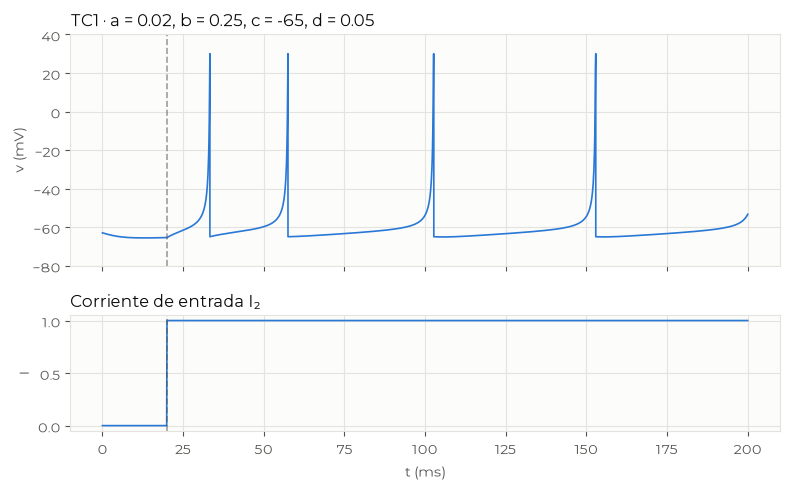

In [ ]:
caso      = casos['TC1']
resultado = resultados['TC1']

I_caso = np.zeros(len(resultado['t']))

for j in range(len(resultado['t'])):
    I_caso[j] = I2(resultado['t'][j])

fig, ax = plt.subplots(
                       2,
                       1,
                       sharex      = True,
                       figsize     = (8, 5),
                       gridspec_kw = {'height_ratios': [2, 1]},
                      )

ax[0].plot(resultado['t_grafico'], resultado['v_grafico'], lw = 1.2, color = COLOR)
ax[0].set_title(f"TC1 · a = {caso['a']}, b = {caso['b']}, c = {caso['c']:.0f}, d = {caso['d']}")
ax[0].set_ylabel('v (mV)')
ax[0].set_ylim(-80, 40)
ax[0].set_yticks(np.arange(-80, 41, 20))

ax[1].plot(resultado['t'], I_caso, lw = 1.2, color = COLOR)
ax[1].set_title('Corriente de entrada I₂')
ax[1].set_ylabel('I')
ax[1].set_xlabel('t (ms)')

for eje in ax:
    for t_cambio in [20]:
        eje.axvline(t_cambio, ls = '--', lw = 1.2, color = TEXTO, alpha = 0.55)

plt.tight_layout()
plt.show()

## 14. Caso estimulado con $I_3$: TC2

La misma neurona tálamo-cortical recibe un pulso negativo entre 20 y 80 ms, que la hiperpolariza; al retirarlo responde con una ráfaga de rebote. El eje de $v$ llega a $-100$ mV para mostrar la hiperpolarización.

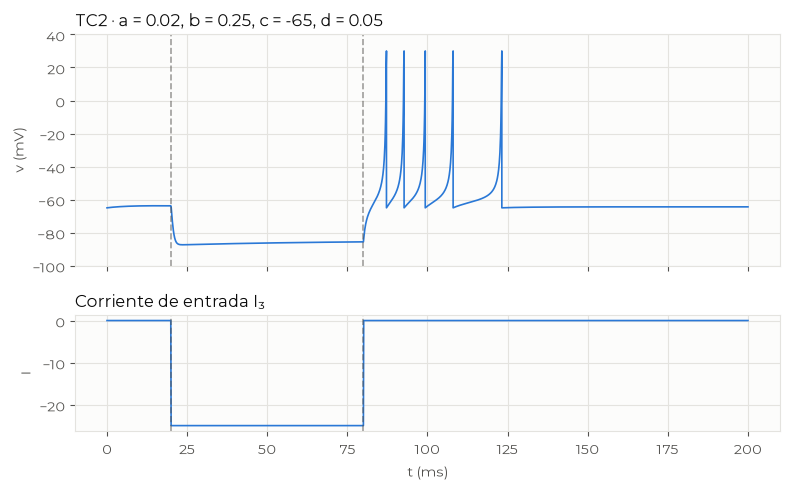

In [ ]:
caso      = casos['TC2']
resultado = resultados['TC2']

I_caso = np.zeros(len(resultado['t']))

for j in range(len(resultado['t'])):
    I_caso[j] = I3(resultado['t'][j])

fig, ax = plt.subplots(
                       2,
                       1,
                       sharex      = True,
                       figsize     = (8, 5),
                       gridspec_kw = {'height_ratios': [2, 1]},
                      )

ax[0].plot(resultado['t_grafico'], resultado['v_grafico'], lw = 1.2, color = COLOR)
ax[0].set_title(f"TC2 · a = {caso['a']}, b = {caso['b']}, c = {caso['c']:.0f}, d = {caso['d']}")
ax[0].set_ylabel('v (mV)')
ax[0].set_ylim(-100, 40)
ax[0].set_yticks(np.arange(-100, 41, 20))

ax[1].plot(resultado['t'], I_caso, lw = 1.2, color = COLOR)
ax[1].set_title('Corriente de entrada I₃')
ax[1].set_ylabel('I')
ax[1].set_xlabel('t (ms)')

for eje in ax:
    for t_cambio in [20, 80]:
        eje.axvline(t_cambio, ls = '--', lw = 1.2, color = TEXTO, alpha = 0.55)

plt.tight_layout()
plt.show()

## 15. Caso estimulado con $I_4$: RZ

El resonador recibe una corriente chica constante desde los 40 ms, que produce oscilaciones subumbrales amortiguadas, y un pulso de 1 ms a los 180 ms que lo lleva al régimen de disparo repetitivo.

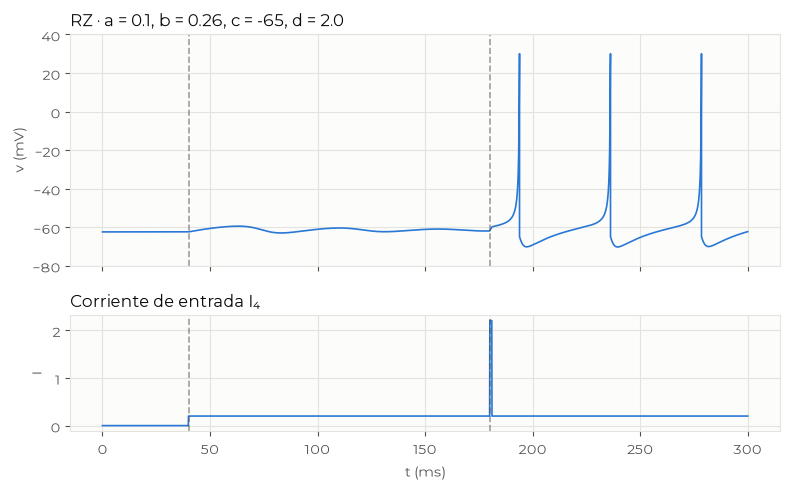

In [ ]:
caso      = casos['RZ']
resultado = resultados['RZ']

I_caso = np.zeros(len(resultado['t']))

for j in range(len(resultado['t'])):
    I_caso[j] = I4(resultado['t'][j])

fig, ax = plt.subplots(
                       2,
                       1,
                       sharex      = True,
                       figsize     = (8, 5),
                       gridspec_kw = {'height_ratios': [2, 1]},
                      )

ax[0].plot(resultado['t_grafico'], resultado['v_grafico'], lw = 1.2, color = COLOR)
ax[0].set_title(f"RZ · a = {caso['a']}, b = {caso['b']}, c = {caso['c']:.0f}, d = {caso['d']}")
ax[0].set_ylabel('v (mV)')
ax[0].set_ylim(-80, 40)
ax[0].set_yticks(np.arange(-80, 41, 20))

ax[1].plot(resultado['t'], I_caso, lw = 1.2, color = COLOR)
ax[1].set_title('Corriente de entrada I₄')
ax[1].set_ylabel('I')
ax[1].set_xlabel('t (ms)')

for eje in ax:
    for t_cambio in [40, 180]:
        eje.axvline(t_cambio, ls = '--', lw = 1.2, color = TEXTO, alpha = 0.55)

plt.tight_layout()
plt.show()

## 16. Los ocho casos en una figura compacta

Figura para el informe, del ancho de una página: una grilla de 2 × 4 casos, cada uno con $v(t)$ y debajo una tira con su corriente de entrada. Los paneles de $v$ comparten el eje vertical para poder comparar los casos; cada corriente muestra sólo sus valores extremos.

In [ ]:
fig = plt.figure(figsize = (7.5, 4.5), layout = 'constrained')
gs  = fig.add_gridspec(4, 4, height_ratios = [3, 1, 3, 1])

for i, nombre in enumerate(casos):
    fila    = 2 * (i // 4)
    columna = i % 4

    resultado = resultados[nombre]
    corriente = casos[nombre]['I']

    I_caso = np.zeros(len(resultado['t']))

    for j in range(len(resultado['t'])):
        I_caso[j] = corriente(resultado['t'][j])

    eje_v = fig.add_subplot(gs[fila, columna])
    eje_I = fig.add_subplot(gs[fila + 1, columna], sharex = eje_v)

    eje_v.plot(resultado['t_grafico'], resultado['v_grafico'], lw = 0.9, color = COLOR)
    eje_v.set_title(nombre, fontsize = 9)
    eje_v.set_ylim(-95, 35)
    eje_v.set_yticks(np.arange(-90, 31, 30))
    eje_v.tick_params(labelsize = 7, labelbottom = False)

    eje_I.plot(resultado['t'], I_caso, lw = 0.9, color = COLOR)
    eje_I.set_yticks([I_caso.min(), I_caso.max()])
    eje_I.tick_params(labelsize = 7)

    if columna == 0:
        eje_v.set_ylabel('v (mV)', fontsize = 8)
        eje_I.set_ylabel('I', fontsize = 8)
    else:
        eje_v.tick_params(labelleft = False)

    if fila == 2:
        eje_I.set_xlabel('t (ms)', fontsize = 8)

plt.show()